Notebook Structure

1. Imports
2. Load Labels
3. Split Patients
4. Create Datasets
5. Create DataLoaders
6. Verify Dataset
7. Verify Batch
8. Verify Labels
9. Verify Image Statistics
10. Check NaNs
11. Check Class Balance
12. Visualize Batch
13. Summary

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
import torch
import matplotlib.pyplot as plt

from src.data.labels import load_labels
from src.data.split_data import split_patients
from src.data.dataset import RSNADataset
from src.data.dataloader import build_dataloader

from src.utils.config import (TRAIN_IMAGES,TRAIN_LABELS)

In [3]:
labels,_ = load_labels(TRAIN_LABELS)

print(f"Patients : {len(labels)}")

Patients : 26684


In [4]:
train_ids, val_ids, test_ids = split_patients(labels)

print(f"TRAIN : {len(train_ids)}")
print(f"VALIDATION : {len(val_ids)}")
print(f"TEST : {len(test_ids)}")


TRAIN : 18678
VALIDATION : 4002
TEST : 4004


In [5]:
train_dataset = RSNADataset(
    patient_ids=train_ids,
    labels=labels,
    image_dir=TRAIN_IMAGES
)

val_dataset = RSNADataset(
    patient_ids=val_ids,
    labels=labels,
    image_dir=TRAIN_IMAGES
)

test_dataset = RSNADataset(
    patient_ids=test_ids,
    labels=labels,
    image_dir=TRAIN_IMAGES
)

In [6]:
train_loader = build_dataloader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = build_dataloader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

test_loader = build_dataloader(
    test_dataset,
    batch_size=8,
    shuffle=False
)

In [ ]:
# First Batch

batch = next(iter(train_loader))

In [8]:
batch.keys()

dict_keys(['image', 'target', 'patient_id'])

In [ ]:
# Tensor Verification

images = batch["image"]

print(type(images))
print(images.dtype)
print(images.shape)

<class 'torch.Tensor'>
torch.float32
torch.Size([8, 1, 512, 512])


In [ ]:
# Label Verification

targets = batch["target"]

print(type(targets))
print(targets.dtype)
print(targets.shape)

print(targets)

<class 'torch.Tensor'>
torch.int64
torch.Size([8])
tensor([0, 0, 1, 0, 1, 0, 1, 1])


In [11]:
batch["patient_id"]

['d30fd0bf-e680-4647-a878-45bab65c8030',
 'a752bc48-905e-4b77-b2ab-257f09b1b8b0',
 'a7c69985-832e-4c35-810c-6578955cec97',
 '22da0004-e69d-49c5-bde5-252ab5895da0',
 'd00de1f7-b96a-4d00-8e22-bc0a6ac67d44',
 '849cbc4f-d4a7-416d-8bdc-550fb6b1eeda',
 '9922146d-a19f-4889-80ca-d6f802118fdb',
 '158cf8f2-8066-42f9-aad0-f52e1bc8de07']

In [14]:
# image stats

print("Minimum : ", images.min().item())
print("Maximum : ", images.max().item())
print("Mean : ", images.mean().item())
print("std : ", images.std().item())

Minimum :  0.0
Maximum :  1.0
Mean :  0.4585287570953369
std :  0.2610728442668915


In [15]:
# NAN check

print(torch.isnan(images).any())

tensor(False)


In [16]:
# INF check

print(torch.isinf(images).any())

tensor(False)


In [18]:
# Label Distribution

unique, counts = torch.unique(
    targets,
    return_counts = True
)

for u,c in zip(unique, counts):
    print(f"Class {u.item()} : {c.item()}")

Class 0 : 4
Class 1 : 4


In [19]:
# Verify image shapes

for img in images:
    print(img.shape)

torch.Size([1, 512, 512])
torch.Size([1, 512, 512])
torch.Size([1, 512, 512])
torch.Size([1, 512, 512])
torch.Size([1, 512, 512])
torch.Size([1, 512, 512])
torch.Size([1, 512, 512])
torch.Size([1, 512, 512])


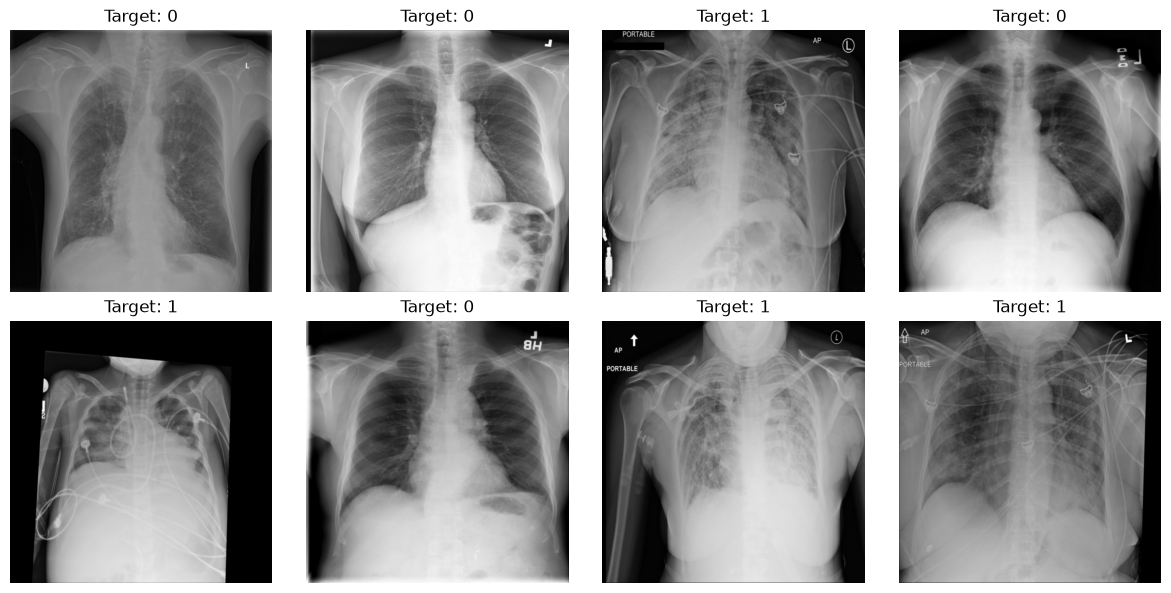

In [20]:
# Visualize batch

fig, axes = plt.subplots(2,4, figsize=(12,6))

axes = axes.flatten()

for i in range(8):

    axes[i].imshow(
        images[i].squeeze(),
        cmap="gray"
    )

    axes[i].set_title(
        f"Target: {targets[i].item()}"
    )

    axes[i].axis("off")

plt.tight_layout()

plt.show()

In [21]:
# Dataset sizes

print("Training Samples  :", len(train_loader.dataset))
print("Validation Samples:", len(val_loader.dataset))
print("Testing Samples   :", len(test_loader.dataset))

Training Samples  : 18678
Validation Samples: 4002
Testing Samples   : 4004


In [22]:
# Number of batches

print("Train Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))
print("Test Batches :", len(test_loader))

Train Batches : 2335
Validation Batches : 501
Test Batches : 501


In [23]:
# Pipeline Verification Summary

print("=" * 60)
print("DATA PIPELINE VERIFICATION")
print("=" * 60)

print("✔ Images loaded successfully")
print("✔ Images converted to tensors")
print("✔ Correct tensor shape")
print("✔ Correct datatype")
print("✔ Labels loaded correctly")
print("✔ No NaN values")
print("✔ No Inf values")
print("✔ DataLoader batching works")
print("✔ Pipeline ready for model training")

DATA PIPELINE VERIFICATION
✔ Images loaded successfully
✔ Images converted to tensors
✔ Correct tensor shape
✔ Correct datatype
✔ Labels loaded correctly
✔ No NaN values
✔ No Inf values
✔ DataLoader batching works
✔ Pipeline ready for model training
